# 02a · Static embeddings: a first look

The step after tokenization: **each token becomes a vector, looked up in a
table.** These vectors are *static*: a token gets the same vector in every
sentence, because nothing has looked at the context yet (that is the job of
the Transformer layers, in `ner_pipeline.ipynb` §5).

Two families of static vectors:

* **BERT-style layer 0** — the first layer of a Transformer encoder adds up
  three looked-up vectors: one for the **token**, one for its **position**
  in the sequence, one for its **segment** (first or second text), and then
  normalizes the sum:

  ```
  layer-0 vector = LayerNorm( token_table[id] + position_table[position] + segment_table[segment] )
  ```

* **Word2Vec-style word vectors** — one table, one vector per *word*,
  looked up by the word itself. No position, no segment.

Tokenization is taken for granted here: it is the subject of
`01a-tokenization-tokens.ipynb`.

## Preparation

### The tokenizers

The tokenizers of `01a`, with the same `tokenizer.tokenize(text)` method
(ByT5 is left out: none of the embeddings below uses bytes).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import spacy
import torch
import transformers
from huggingface_hub.utils import logging as hub_logging
from transformers import AutoModel, AutoTokenizer

from ner_helpers import show_embeddings   # draws vectors as colored boxes

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
hub_logging.set_verbosity_error()


class SpacyTokenizer:
    # gives a spaCy tokenizer the same .tokenize(text) method as the Hugging Face ones
    def __init__(self, model):
        self.nlp = spacy.load(model) if model != "blank" else spacy.blank("en")
    def tokenize(self, text):
        return [t.text for t in self.nlp.tokenizer(text)]


TOKENIZERS = {
    "Rule-based (scispaCy)":     SpacyTokenizer("en_core_sci_sm"),
    "Rule-based (spaCy)":        SpacyTokenizer("blank"),
    "WordPiece (BERT, uncased)": AutoTokenizer.from_pretrained("d4data/biomedical-ner-all"),
    "WordPiece (BiomedBERT)":    AutoTokenizer.from_pretrained(
                                     "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext"),
    "BPE (RoBERTa)":             AutoTokenizer.from_pretrained("roberta-base"),
    "Unigram (ALBERT)":          AutoTokenizer.from_pretrained("albert-base-v2"),
}

# The walkthrough sentence of ner_pipeline.ipynb and the five words of 01a.
sentence = ("A 44-year-old woman presented with a 3-day history of right flank and lower "
            "quadrant abdominal pain associated with nausea and constipation.")
WORDS = ["constipation", "hypokalemia", "dyspnea", "echocardiography", "44-year-old"]

### The embedding approaches

Each approach below is called with a list of tokens and returns a table with
one row per token: the token, its **id** (the row of the token table it
reads), its **position** and **segment**, the three looked-up vectors and
their normalized sum, the **layer-0 vector** — the input of the first
Transformer layer.

Read `__call__` of `TransformerEmbeddings`: it is the formula above, step by
step. The last lines check the hand-made sum against the model's own
embedding layer.

For the Word2Vec side we use the static vectors of spaCy's `en_core_web_md`
(the same ones as §2 of `ner_pipeline.ipynb`). They are not Google's
original Word2Vec model (3.6 GB), but they work the same way: one vector per
word, looked up by the word's text.

In [2]:
class TransformerEmbeddings:
    # layer 0 of a Hugging Face encoder: its token, position and segment tables
    def __init__(self, model_name, tokenizer, first_position=0, separators=1):
        self.tokenizer = tokenizer                                     # name of its own tokenizer in TOKENIZERS
        self.vocab = AutoTokenizer.from_pretrained(model_name)         # token string → id
        self.layer = AutoModel.from_pretrained(model_name).embeddings  # keep layer 0, drop the rest
        self.first_position = first_position                           # RoBERTa counts positions from 2
        self.separators = separators                                   # RoBERTa puts 2 separators between texts

    def __call__(self, tokens, tokens_b=None):
        # 1. add the special tokens:  [CLS] tokens [SEP]  (tokens_b [SEP])
        cls, sep = self.vocab.cls_token, self.vocab.sep_token
        seq = [cls] + tokens + [sep]
        segments = [0] * len(seq)
        if tokens_b is not None:
            seq += [sep] * (self.separators - 1) + tokens_b + [sep]
            segments += [1] * (len(seq) - len(segments))

        # 2. three indices per token
        ids = torch.tensor(self.vocab.convert_tokens_to_ids(seq))     # a string missing from the vocabulary → [UNK]
        positions = torch.arange(len(seq)) + self.first_position
        segment_table = getattr(self.layer, "token_type_embeddings", None)   # DistilBERT has none
        if segment_table is not None and segment_table.num_embeddings == 1:   # RoBERTa has a single segment
            segments = [0] * len(seq)
        segments = torch.tensor(segments)

        # 3. look up the three tables, add, normalize
        with torch.no_grad():
            token_vecs = self.layer.word_embeddings(ids)
            position_vecs = self.layer.position_embeddings(positions)
            segment_vecs = segment_table(segments) if segment_table is not None else None
            total = token_vecs + position_vecs + (segment_vecs if segment_vecs is not None else 0)
            layer0 = self.layer.LayerNorm(total)

            # check: the model's own embedding layer gives the same vectors
            extra = {"token_type_ids": segments[None]} if segment_table is not None else {}
            same = torch.allclose(layer0, self.layer(input_ids=ids[None], **extra)[0], atol=1e-5)

        unk = self.vocab.unk_token_id
        n = len(seq)
        table = pd.DataFrame({
            "token": seq,
            "id": [f"{i} = {self.vocab.unk_token}" if i == unk and t != self.vocab.unk_token else i
                   for i, t in zip(ids.tolist(), seq)],
            "position": positions.tolist(),
            "segment": segments.tolist() if segment_table is not None else [None] * n,
            "token embedding": list(token_vecs.numpy()),
            "position embedding": list(position_vecs.numpy()),
            "segment embedding": list(segment_vecs.numpy()) if segment_vecs is not None else [None] * n,
            "layer 0 = LayerNorm(sum)": list(layer0.numpy()),
        })
        table.attrs["same_scale"] = ["token embedding", "position embedding", "segment embedding"]
        table.attrs["note"] = f"check — the sum above equals the model's own layer 0: {same}"
        return table


class WordVectors:
    # Word2Vec-style static vectors: one table, looked up by the word itself
    def __init__(self, spacy_model, tokenizer):
        self.tokenizer = tokenizer                                     # name of its own tokenizer in TOKENIZERS
        self.vectors = spacy.load(spacy_model).vocab.vectors           # rows × dimensions

    def __call__(self, tokens, tokens_b=None):
        seq = tokens + (tokens_b or [])                                # no special tokens, no segments
        rows = [self.vectors.find(key=t) for t in seq]                 # -1: the word is not in the table
        zero = np.zeros(self.vectors.shape[1], dtype="float32")
        n = len(seq)
        table = pd.DataFrame({
            "token": seq,
            "id": [r if r >= 0 else "— (not in the table: zero vector)" for r in rows],
            "position": [None] * n,
            "segment": [None] * n,
            "token embedding": [self.vectors.data[r] if r >= 0 else zero for r in rows],
            "position embedding": [None] * n,
            "segment embedding": [None] * n,
            "layer 0 = LayerNorm(sum)": [None] * n,
        })
        return table


EMBEDDINGS = {
    # name                          model                                          its own tokenizer
    "BERT (uncased)":            TransformerEmbeddings("bert-base-uncased",          "WordPiece (BERT, uncased)"),
    "DistilBERT (ner_pipeline)": TransformerEmbeddings("d4data/biomedical-ner-all",  "WordPiece (BERT, uncased)"),
    "BiomedBERT":                TransformerEmbeddings(
                                     "microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext",
                                                                                     "WordPiece (BiomedBERT)"),
    "RoBERTa":                   TransformerEmbeddings("roberta-base",               "BPE (RoBERTa)",
                                                       first_position=2, separators=2),
    "ALBERT":                    TransformerEmbeddings("albert-base-v2",             "Unigram (ALBERT)"),
    "Word2Vec-style (spaCy)":    WordVectors("en_core_web_md",                       "Rule-based (spaCy)"),
}

The tables inside each approach (rows × dimensions):

In [3]:
def shape(table):
    return "—" if table is None else f"{table.weight.shape[0]:,} × {table.weight.shape[1]}"

overview = {}
for name, e in EMBEDDINGS.items():
    if isinstance(e, WordVectors):
        overview[name] = {"tokenizer": e.tokenizer,
                          "token table": f"{e.vectors.shape[0]:,} × {e.vectors.shape[1]}",
                          "position table": "—", "segment table": "—"}
    else:
        overview[name] = {"tokenizer": e.tokenizer,
                          "token table": shape(e.layer.word_embeddings),
                          "position table": shape(e.layer.position_embeddings),
                          "segment table": shape(getattr(e.layer, "token_type_embeddings", None))}
pd.DataFrame(overview).T

,tokenizer,token table,position table,segment table
BERT (uncased),"WordPiece (BERT, uncased)","30,522 × 768",512 × 768,2 × 768
DistilBERT (ner_pipeline),"WordPiece (BERT, uncased)","30,522 × 768",512 × 768,—
BiomedBERT,WordPiece (BiomedBERT),"30,522 × 768",512 × 768,2 × 768
RoBERTa,BPE (RoBERTa),"50,265 × 768",514 × 768,1 × 768
ALBERT,Unigram (ALBERT),"30,000 × 128",512 × 128,2 × 128
Word2Vec-style (spaCy),Rule-based (spaCy),"20,000 × 300",—,—


### How to read the boxes

Each vector is drawn as a block of tiny boxes, **one box per dimension**
(48 per line: a 768-dimensional vector is 16 lines), colored from
**red** (negative) through **white** (≈ 0) to **blue** (positive).

* The three looked-up vectors (token, position, segment) share **one color
  scale** — they are added together, so their strengths can be compared.
* The layer-0 vector has its own scale (LayerNorm changes the magnitudes).
* Full red or blue means 2 standard deviations or more away from zero
  (computed on the vectors shown in the table).

## The routine

Pick an embedding approach by name: **its own tokenizer is chosen
automatically** (the second line). Then each of the five clinical words is
tokenized and looked up. **Change the name in the first line** (copy one
from the list above) and run the cell again.

embedding: BERT (uncased)   |   tokenizer: WordPiece (BERT, uncased)


token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,0,,,,
con,9530,1,0,,,,
##sti,16643,2,0,,,,
##pati,24952,3,0,,,,
##on,2239,4,0,,,,
[SEP],102,5,0,,,,

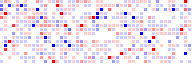
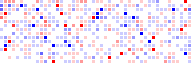
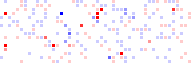
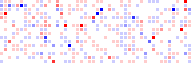
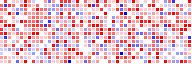
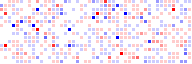
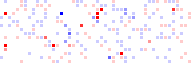
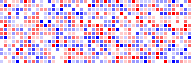
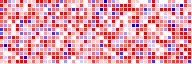
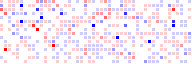
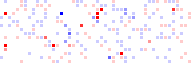
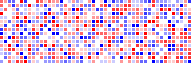
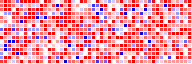
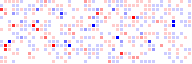
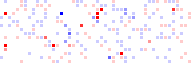
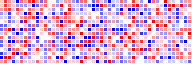
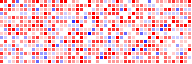
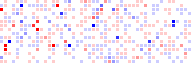
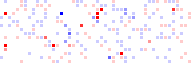
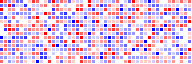
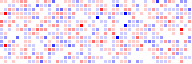
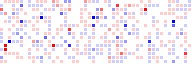
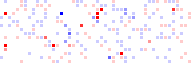
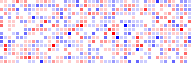

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,0,,,,
h,1044,1,0,,,,
##yp,22571,2,0,,,,
##oka,12352,3,0,,,,
##lem,16930,4,0,,,,
##ia,2401,5,0,,,,
[SEP],102,6,0,,,,

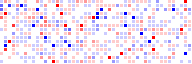
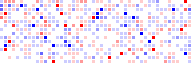
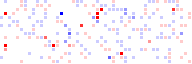
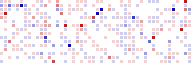
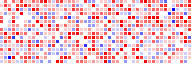
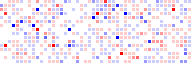
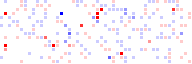
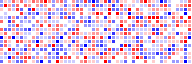
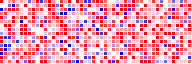
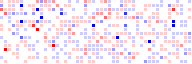
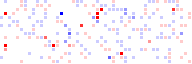
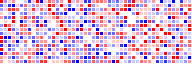
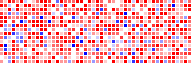
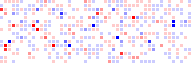
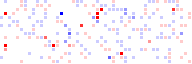
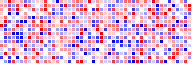
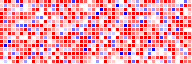
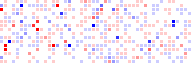
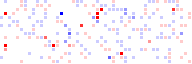
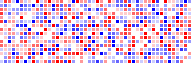
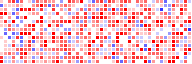
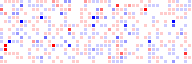
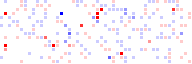
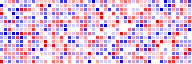
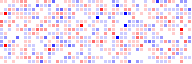
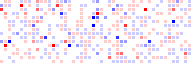
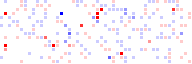
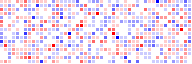

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,0,,,,
d,1040,1,0,,,,
##ys,7274,2,0,,,,
##p,2361,3,0,,,,
##nea,22084,4,0,,,,
[SEP],102,5,0,,,,

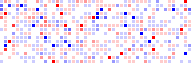
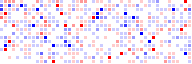
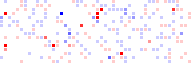
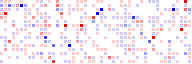
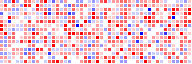
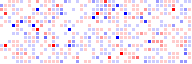
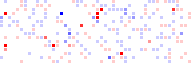
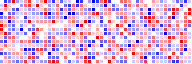
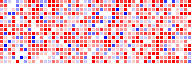
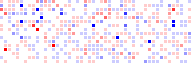
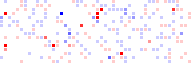
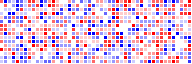
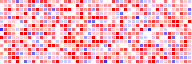
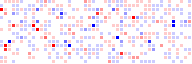
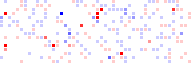
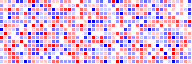
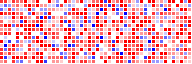
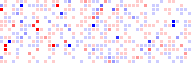
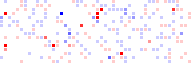
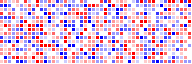
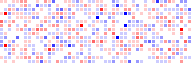
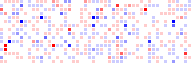
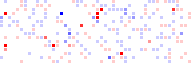
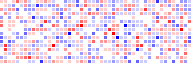

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,0,,,,
echo,9052,1,0,,,,
##card,11522,2,0,,,,
##iography,26535,3,0,,,,
[SEP],102,4,0,,,,

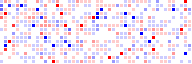
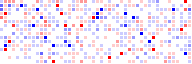
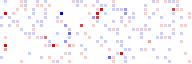
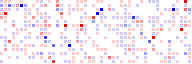
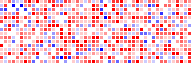
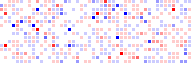
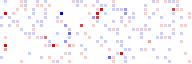
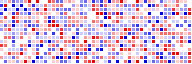
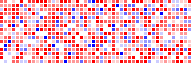
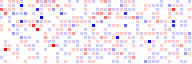
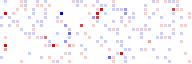
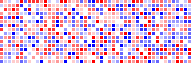
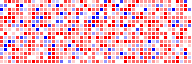
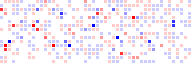
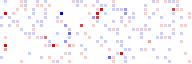
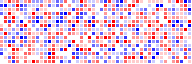
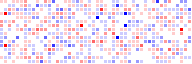
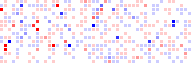
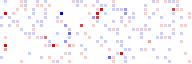
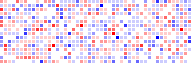

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,0,,,,
44,4008,1,0,,,,
-,1011,2,0,,,,
year,2095,3,0,,,,
-,1011,4,0,,,,
old,2214,5,0,,,,
[SEP],102,6,0,,,,

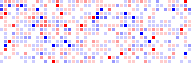
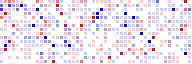
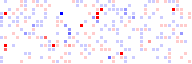
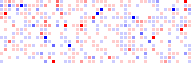
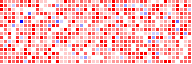
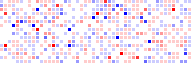
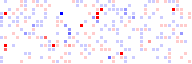
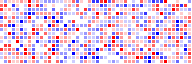
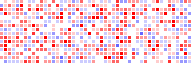
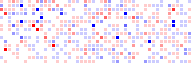
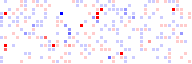
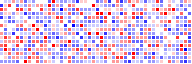
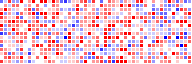
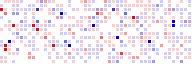
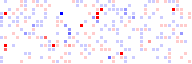
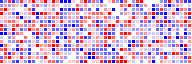
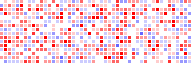
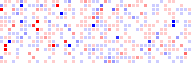
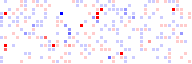
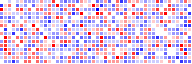
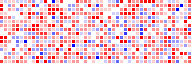
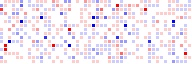
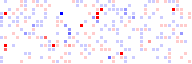
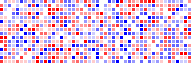
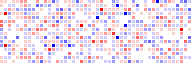
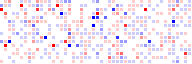
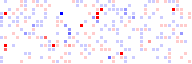
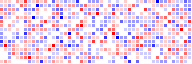

In [4]:
name = "BERT (uncased)"                         # ← change me
embedding = EMBEDDINGS[name]
tokenizer = TOKENIZERS[embedding.tokenizer]     # the embedding's own tokenizer

print(f"embedding: {name}   |   tokenizer: {embedding.tokenizer}")
for w in WORDS:
    show_embeddings(embedding(tokenizer.tokenize(w)), title=w)

## The same routine, for every embedding approach

══ BERT (uncased)   |   tokenizer: WordPiece (BERT, uncased)


token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,0,,,,
con,9530,1,0,,,,
##sti,16643,2,0,,,,
##pati,24952,3,0,,,,
##on,2239,4,0,,,,
[SEP],102,5,0,,,,

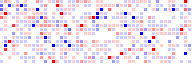
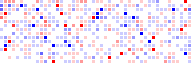
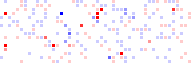
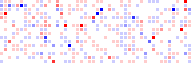
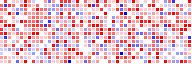
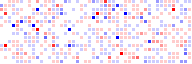
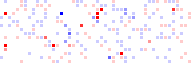
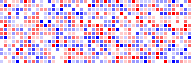
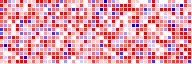
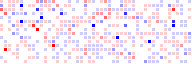
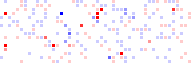
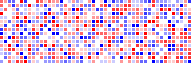
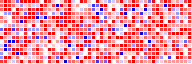
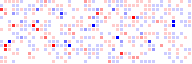
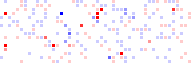
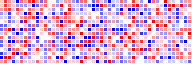
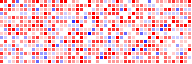
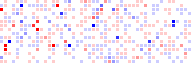
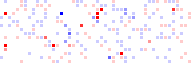
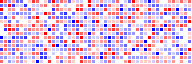
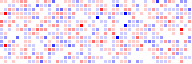
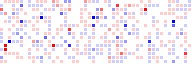
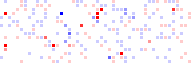
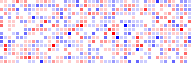

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,0,,,,
h,1044,1,0,,,,
##yp,22571,2,0,,,,
##oka,12352,3,0,,,,
##lem,16930,4,0,,,,
##ia,2401,5,0,,,,
[SEP],102,6,0,,,,

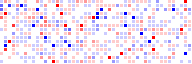
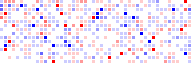
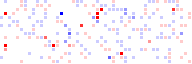
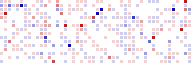
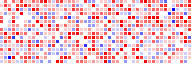
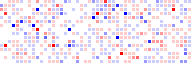
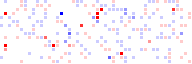
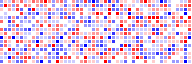
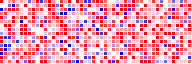
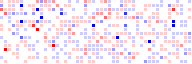
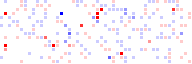
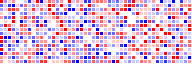
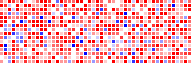
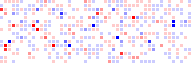
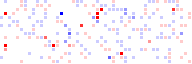
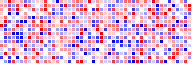
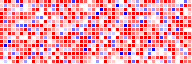
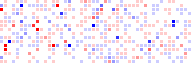
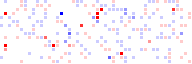
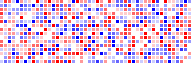
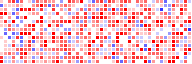
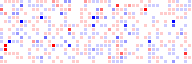
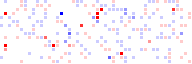
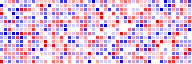
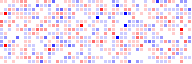
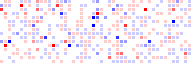
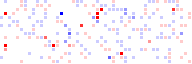
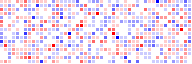

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,0,,,,
d,1040,1,0,,,,
##ys,7274,2,0,,,,
##p,2361,3,0,,,,
##nea,22084,4,0,,,,
[SEP],102,5,0,,,,

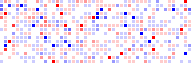
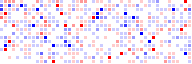
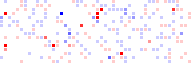
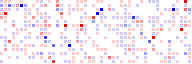
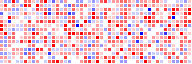
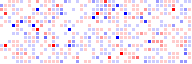
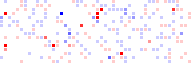
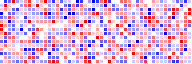
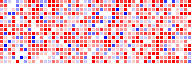
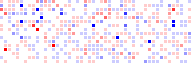
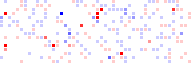
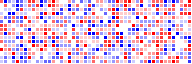
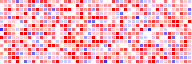
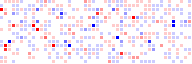
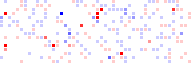
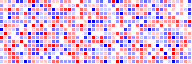
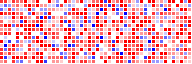
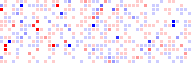
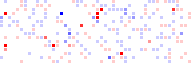
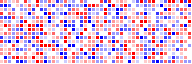
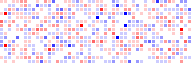
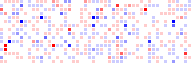
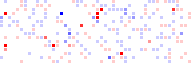
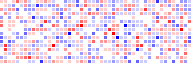

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,0,,,,
echo,9052,1,0,,,,
##card,11522,2,0,,,,
##iography,26535,3,0,,,,
[SEP],102,4,0,,,,

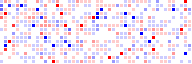
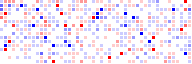
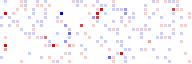
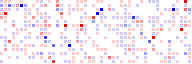
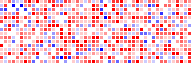
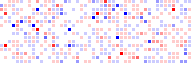
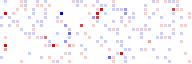
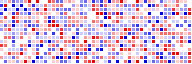
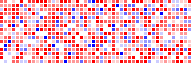
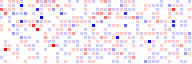
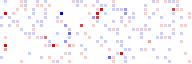
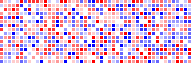
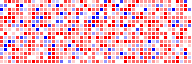
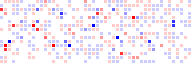
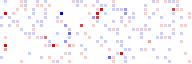
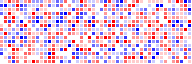
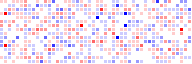
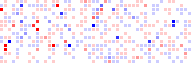
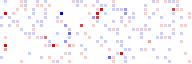
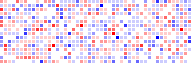

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,0,,,,
44,4008,1,0,,,,
-,1011,2,0,,,,
year,2095,3,0,,,,
-,1011,4,0,,,,
old,2214,5,0,,,,
[SEP],102,6,0,,,,

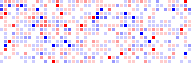
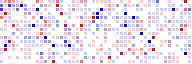
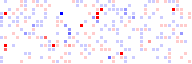
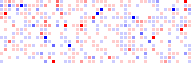
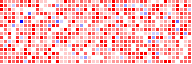
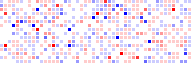
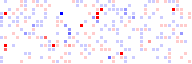
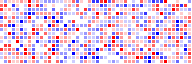
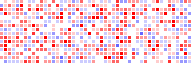
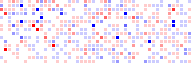
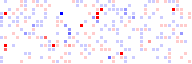
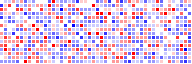
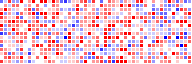
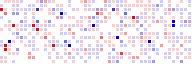
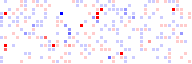
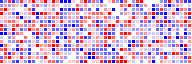
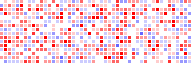
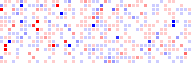
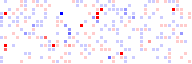
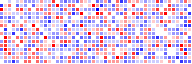
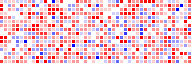
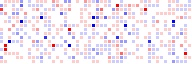
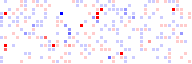
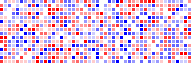
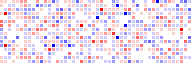
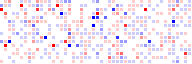
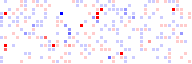
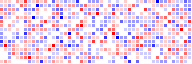

══ DistilBERT (ner_pipeline)   |   tokenizer: WordPiece (BERT, uncased)


token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,—,,,—,
con,9530,1,—,,,—,
##sti,16643,2,—,,,—,
##pati,24952,3,—,,,—,
##on,2239,4,—,,,—,
[SEP],102,5,—,,,—,

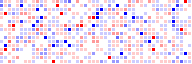
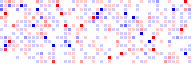
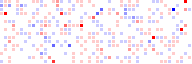
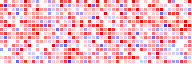
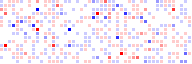
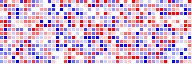
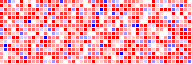
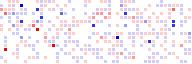
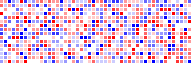
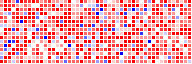
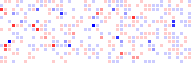
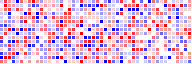
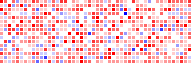
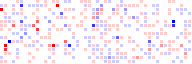
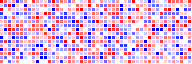
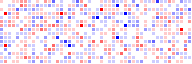
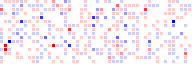
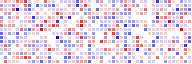

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,—,,,—,
h,1044,1,—,,,—,
##yp,22571,2,—,,,—,
##oka,12352,3,—,,,—,
##lem,16930,4,—,,,—,
##ia,2401,5,—,,,—,
[SEP],102,6,—,,,—,

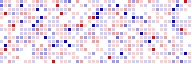
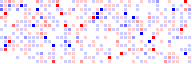
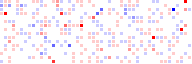
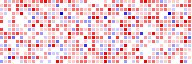
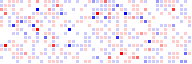
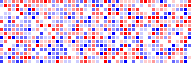
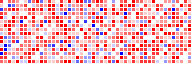
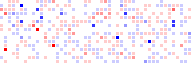
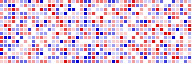
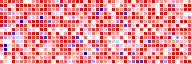
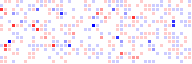
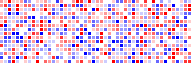
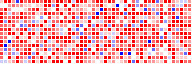
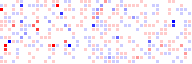
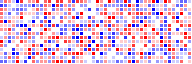
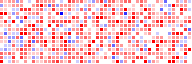
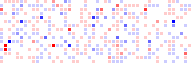
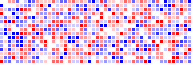
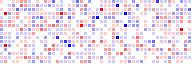
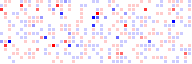
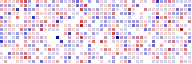

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,—,,,—,
d,1040,1,—,,,—,
##ys,7274,2,—,,,—,
##p,2361,3,—,,,—,
##nea,22084,4,—,,,—,
[SEP],102,5,—,,,—,

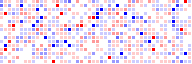
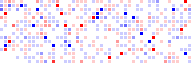
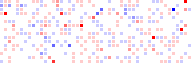
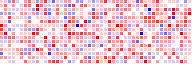
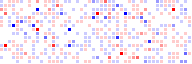
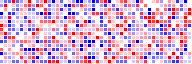
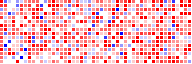
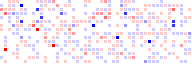
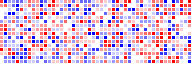
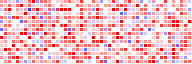
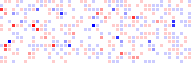
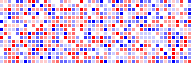
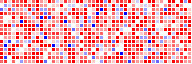
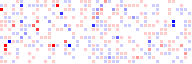
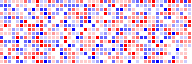
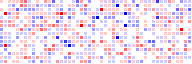
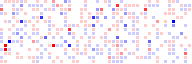
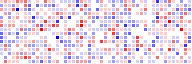

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,—,,,—,
echo,9052,1,—,,,—,
##card,11522,2,—,,,—,
##iography,26535,3,—,,,—,
[SEP],102,4,—,,,—,

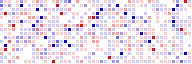
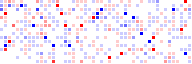
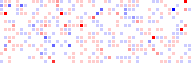
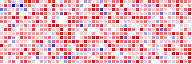
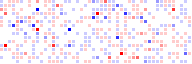
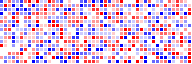
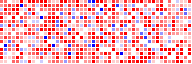
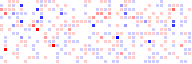
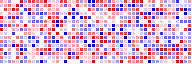
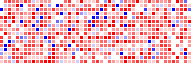
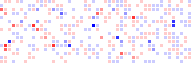
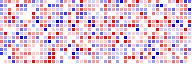
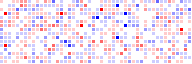
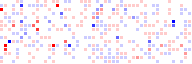
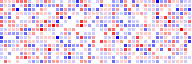

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,—,,,—,
44,4008,1,—,,,—,
-,1011,2,—,,,—,
year,2095,3,—,,,—,
-,1011,4,—,,,—,
old,2214,5,—,,,—,
[SEP],102,6,—,,,—,

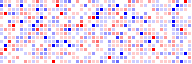
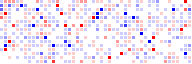
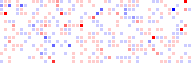
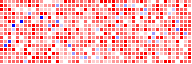
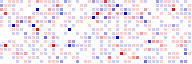
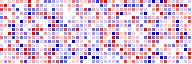
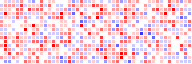
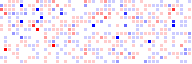
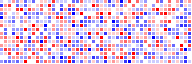
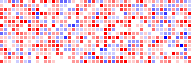
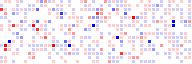
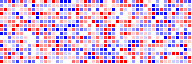
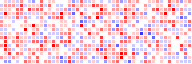
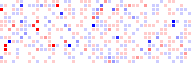
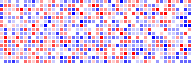
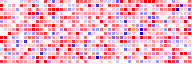
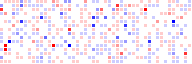
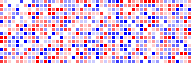
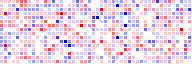
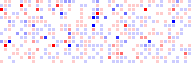
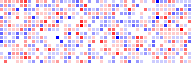

══ BiomedBERT   |   tokenizer: WordPiece (BiomedBERT)


token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],2,0,0,,,,
constipation,19618,1,0,,,,
[SEP],3,2,0,,,,

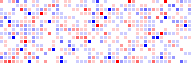
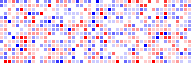
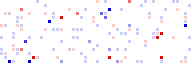
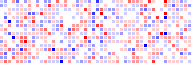
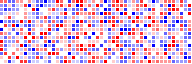
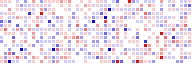
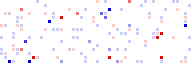
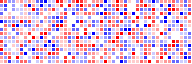
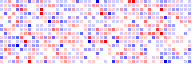
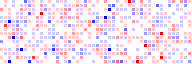
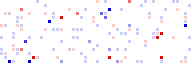
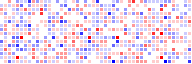

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],2,0,0,,,,
hypo,14395,1,0,,,,
##ka,7640,2,0,,,,
##le,1952,3,0,,,,
##mia,6026,4,0,,,,
[SEP],3,5,0,,,,

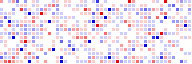
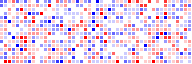
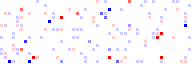
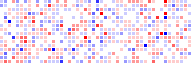
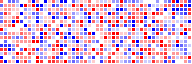
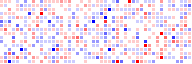
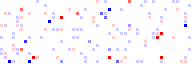
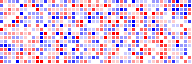
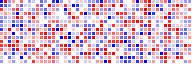
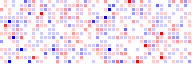
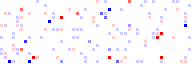
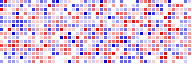
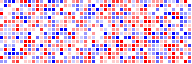
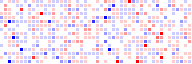
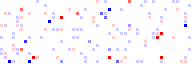
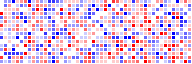
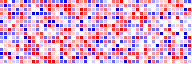
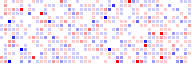
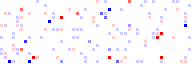
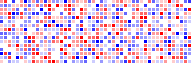
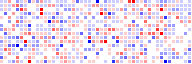
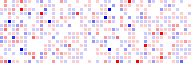
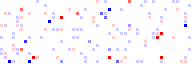
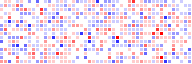

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],2,0,0,,,,
dyspnea,18461,1,0,,,,
[SEP],3,2,0,,,,

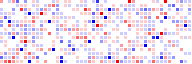
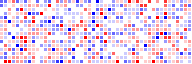
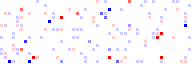
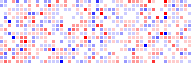
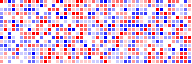
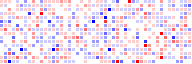
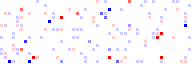
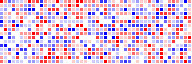
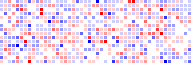
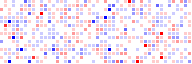
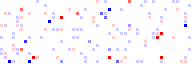
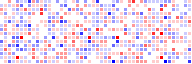

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],2,0,0,,,,
echocardiography,12814,1,0,,,,
[SEP],3,2,0,,,,

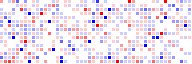
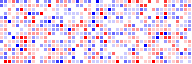
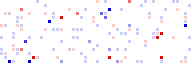
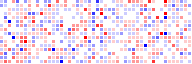
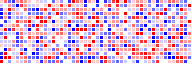
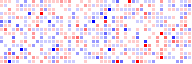
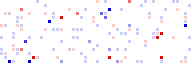
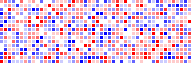
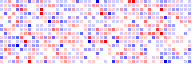
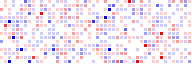
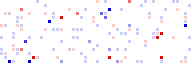
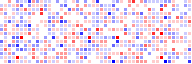

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],2,0,0,,,,
44,4044,1,0,,,,
-,17,2,0,,,,
year,2476,3,0,,,,
-,17,4,0,,,,
old,4156,5,0,,,,
[SEP],3,6,0,,,,

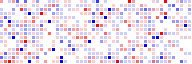
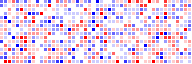
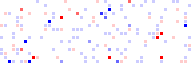
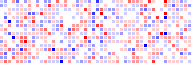
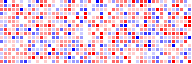
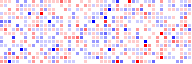
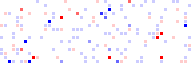
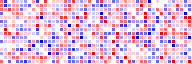
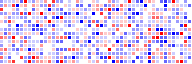
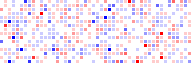
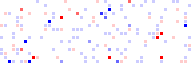
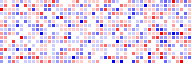
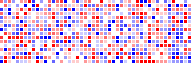
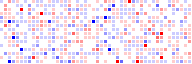
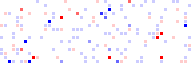
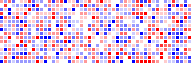
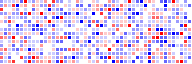
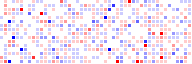
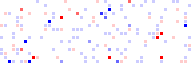
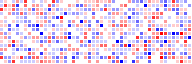
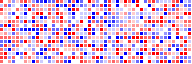
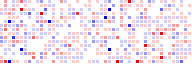
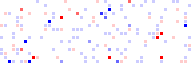
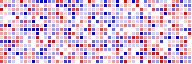
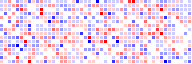
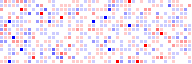
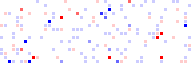
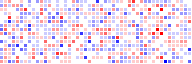

══ RoBERTa   |   tokenizer: BPE (RoBERTa)


token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
<s>,0,2,0,,,,
const,20836,3,0,,,,
ipation,33412,4,0,,,,
</s>,2,5,0,,,,

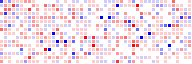
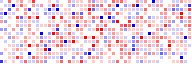
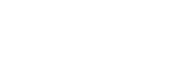
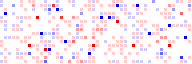
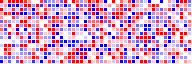
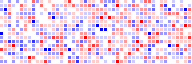
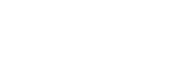
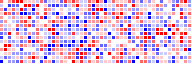
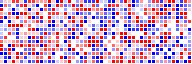
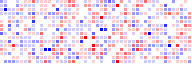
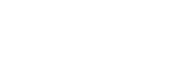
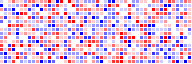
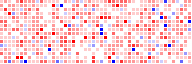
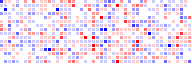
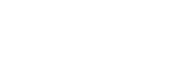
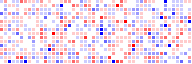

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
<s>,0,2,0,,,,
hyp,33027,3,0,,,,
ok,1638,4,0,,,,
al,337,5,0,,,,
emia,23249,6,0,,,,
</s>,2,7,0,,,,

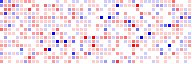
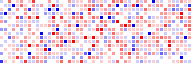
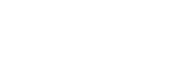
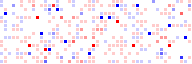
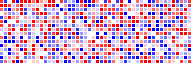
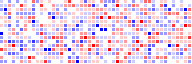
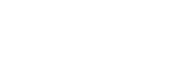
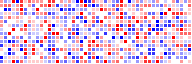
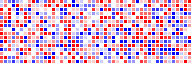
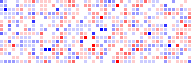
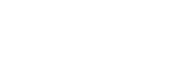
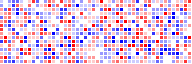
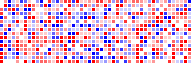
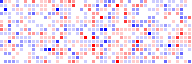
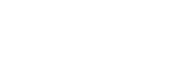
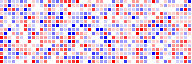
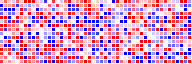
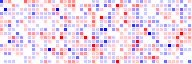
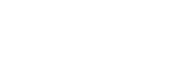
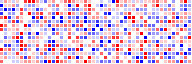
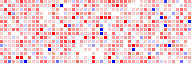
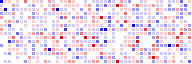
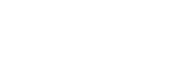
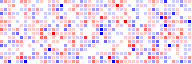

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
<s>,0,2,0,,,,
d,417,3,0,,,,
ys,2459,4,0,,,,
p,642,5,0,,,,
nea,22423,6,0,,,,
</s>,2,7,0,,,,

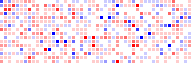
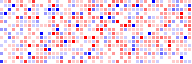
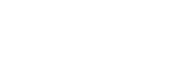
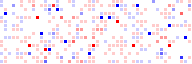
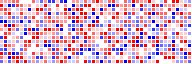
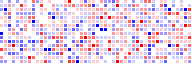
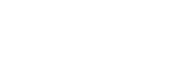
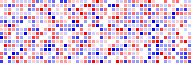
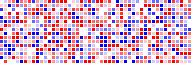
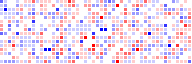
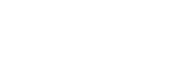
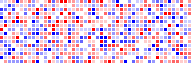
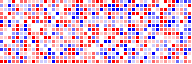
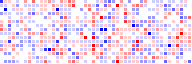
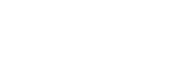
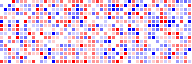
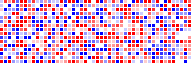
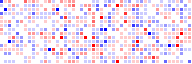
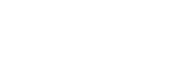
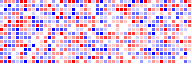
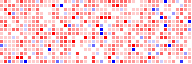
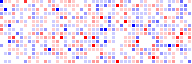
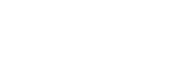
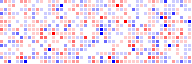

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
<s>,0,2,0,,,,
ech,7529,3,0,,,,
oc,1975,4,0,,,,
ardi,11147,5,0,,,,
ography,10486,6,0,,,,
</s>,2,7,0,,,,

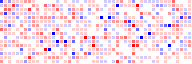
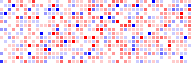
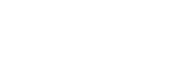
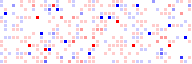
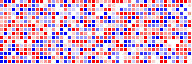
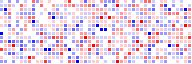
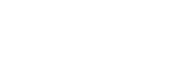
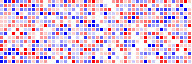
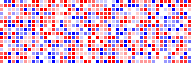
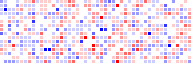
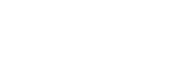
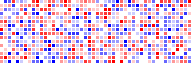
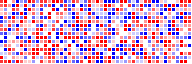
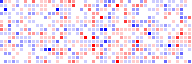
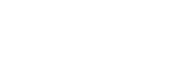
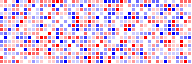
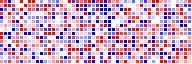
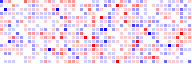
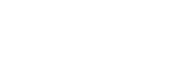
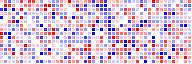
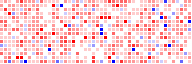
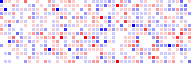
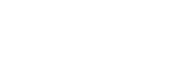
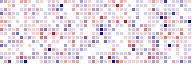

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
<s>,0,2,0,,,,
44,3305,3,0,,,,
-,12,4,0,,,,
year,180,5,0,,,,
-,12,6,0,,,,
old,279,7,0,,,,
</s>,2,8,0,,,,

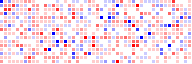
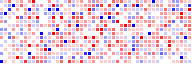
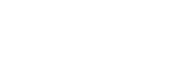
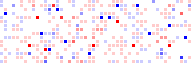
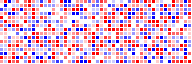
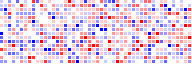
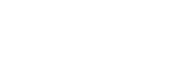
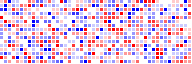
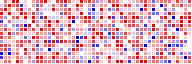
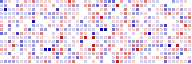
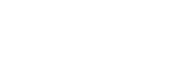
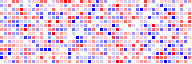
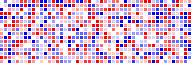
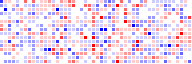
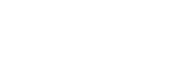
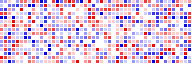
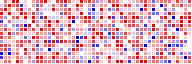
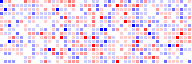
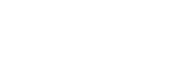
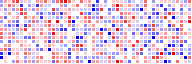
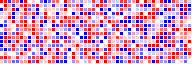
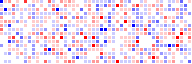
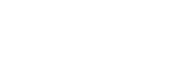
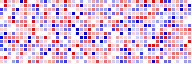
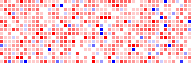
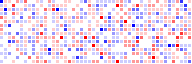
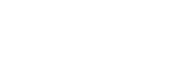
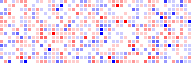

══ ALBERT   |   tokenizer: Unigram (ALBERT)


token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],2,0,0,,,,
▁cons,11608,1,0,,,,
tip,10169,2,0,,,,
ation,857,3,0,,,,
[SEP],3,4,0,,,,


token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],2,0,0,,,,
▁hypo,8772,1,0,,,,
kal,6766,2,0,,,,
emia,11461,3,0,,,,
[SEP],3,4,0,,,,


token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],2,0,0,,,,
▁dys,14903,1,0,,,,
p,306,2,0,,,,
nea,9894,3,0,,,,
[SEP],3,4,0,,,,


token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],2,0,0,,,,
▁echo,8117,1,0,,,,
cardi,19278,2,0,,,,
ography,10112,3,0,,,,
[SEP],3,4,0,,,,


token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],2,0,0,,,,
▁44,4576,1,0,,,,
-,8,2,0,,,,
year,731,3,0,,,,
-,8,4,0,,,,
old,1218,5,0,,,,
[SEP],3,6,0,,,,


... (2 outputs left out)

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
hypokalemia,19036,—,—,,—,—,—


token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
dyspnea,18050,—,—,,—,—,—


token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
echocardiography,18873,—,—,,—,—,—


token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
44,4442,—,—,,—,—,—
-,9,—,—,,—,—,—
year,142,—,—,,—,—,—
-,9,—,—,,—,—,—
old,245,—,—,,—,—,—


In [5]:
for name, embedding in EMBEDDINGS.items():
    tokenizer = TOKENIZERS[embedding.tokenizer]
    print(f"══ {name}   |   tokenizer: {embedding.tokenizer}")
    for w in WORDS:
        show_embeddings(embedding(tokenizer.tokenize(w)), title=w)

## A whole sentence

Now the full walkthrough sentence (the `sentence` variable of the
preparation cell). Again, **change the name in the first line** to try
another approach.

A 44-year-old woman presented with a 3-day history of right flank and lower quadrant abdominal pain associated with nausea and constipation. 



token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,0,,,,
a,1037,1,0,,,,
44,4008,2,0,,,,
-,1011,3,0,,,,
year,2095,4,0,,,,
-,1011,5,0,,,,
old,2214,6,0,,,,
woman,2450,7,0,,,,
presented,3591,8,0,,,,
with,2007,9,0,,,,

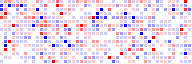
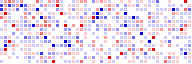
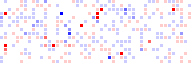
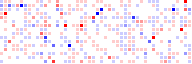
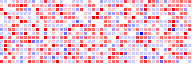
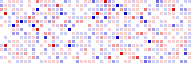
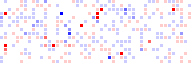
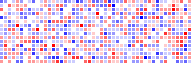
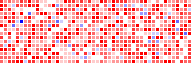
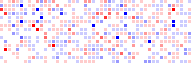
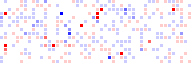
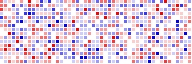
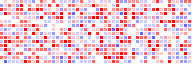
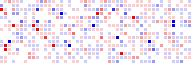
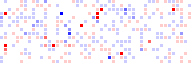
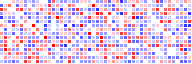
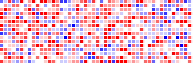
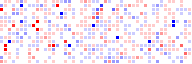
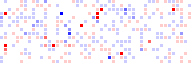
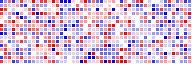
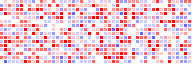
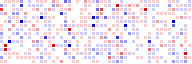
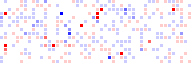
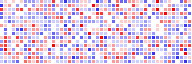
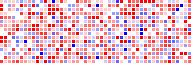
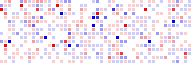
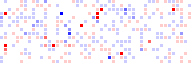
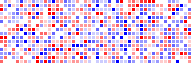
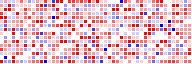
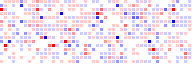
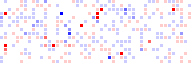
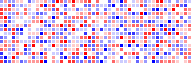
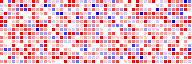
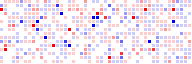
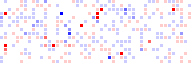
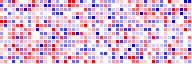
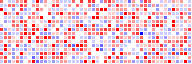
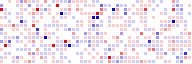
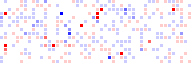
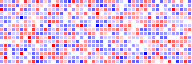
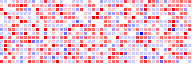
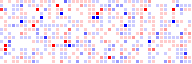
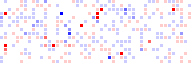
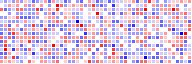
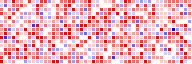
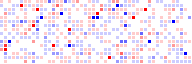
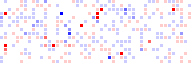
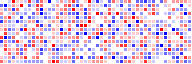
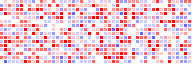
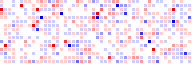
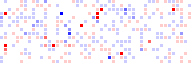
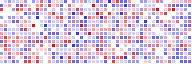
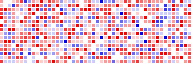
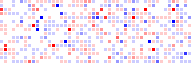
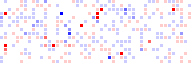
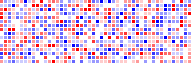
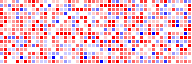
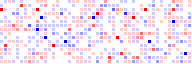
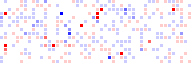
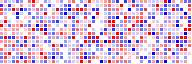
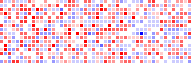
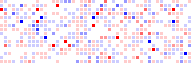
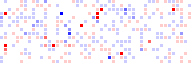
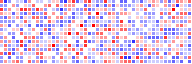
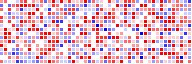
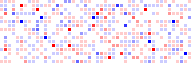
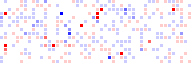
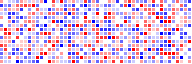
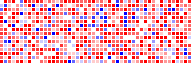
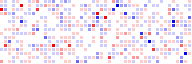
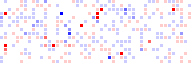
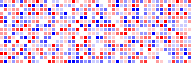
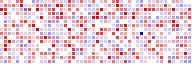
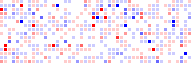
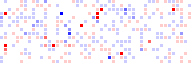
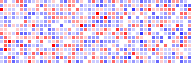
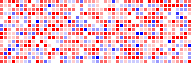
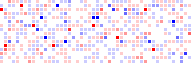
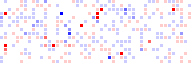
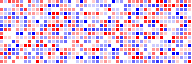
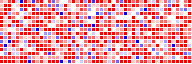
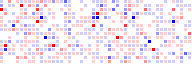
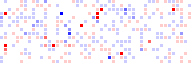
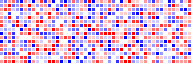
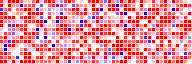
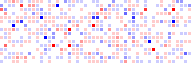
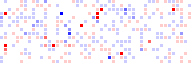
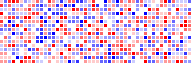
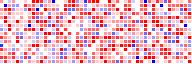
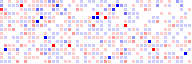
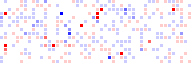
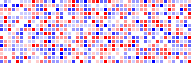
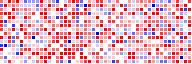
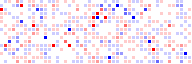
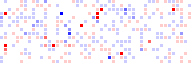
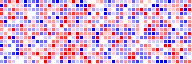
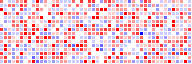
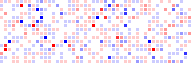
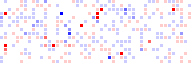
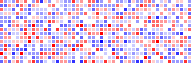
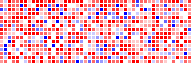
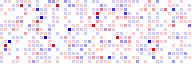
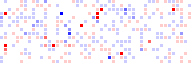
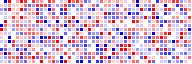
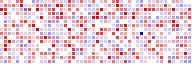
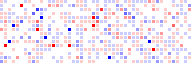
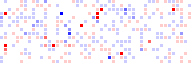
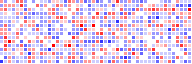
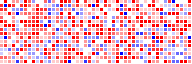
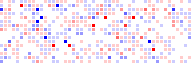
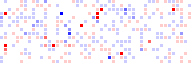
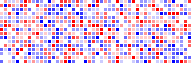
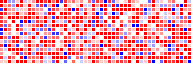
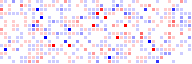
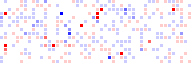
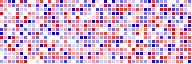
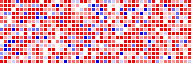
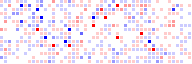
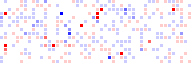
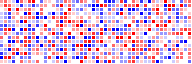
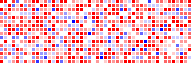
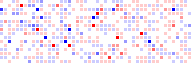
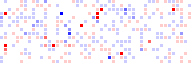
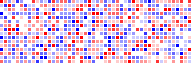
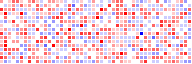
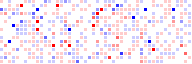
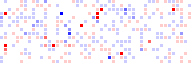
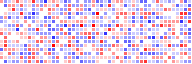
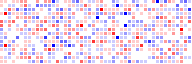
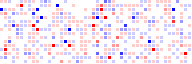
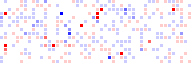
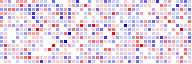

In [6]:
name = "BERT (uncased)"                         # ← change me
embedding = EMBEDDINGS[name]
tokenizer = TOKENIZERS[embedding.tokenizer]

print(sentence, "\n")
show_embeddings(embedding(tokenizer.tokenize(sentence)), title=f"{name}   |   tokenizer: {embedding.tokenizer}")

## The whole sentence, for every embedding approach

A 44-year-old woman presented with a 3-day history of right flank and lower quadrant abdominal pain associated with nausea and constipation. 



token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,0,,,,
a,1037,1,0,,,,
44,4008,2,0,,,,
-,1011,3,0,,,,
year,2095,4,0,,,,
-,1011,5,0,,,,
old,2214,6,0,,,,
woman,2450,7,0,,,,
presented,3591,8,0,,,,
with,2007,9,0,,,,

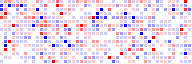
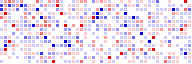
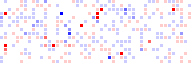
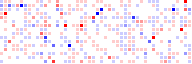
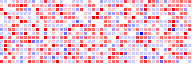
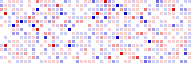
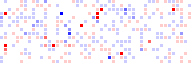
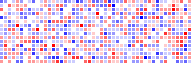
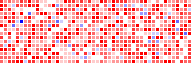
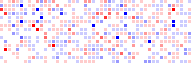
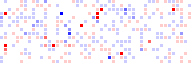
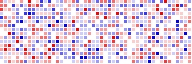
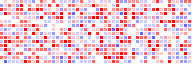
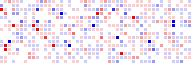
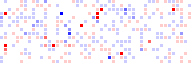
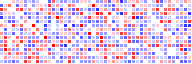
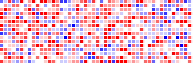
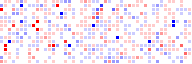
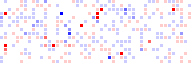
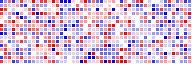
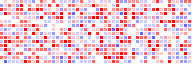
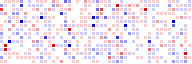
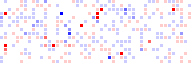
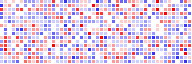
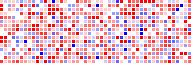
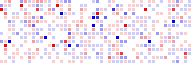
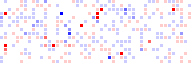
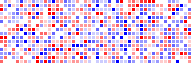
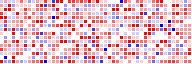
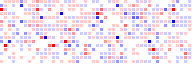
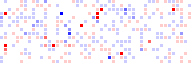
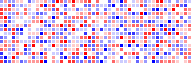
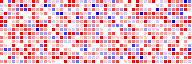
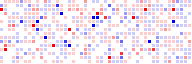
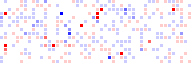
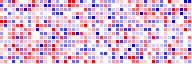
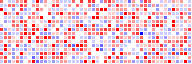
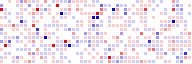
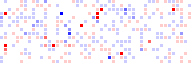
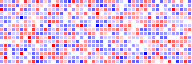
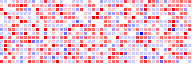
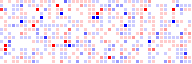
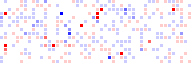
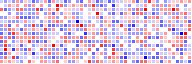
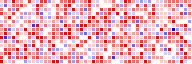
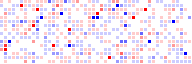
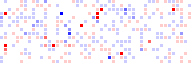
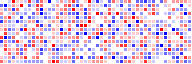
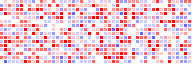
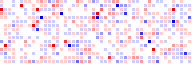
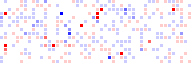
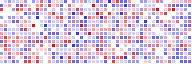
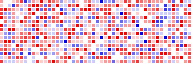
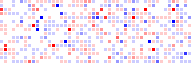
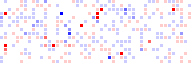
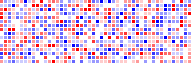
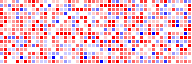
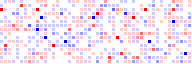
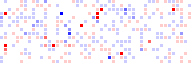
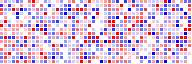
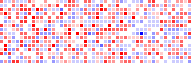
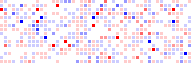
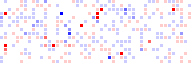
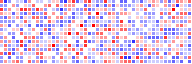
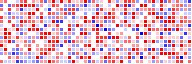
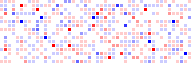
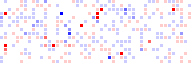
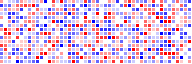
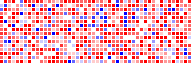
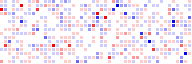
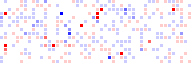
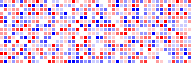
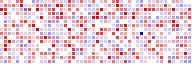
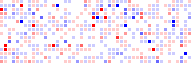
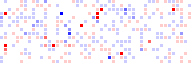
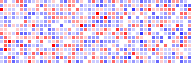
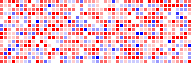
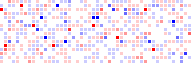
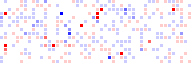
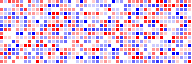
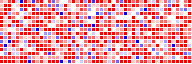
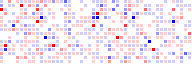
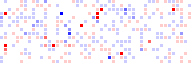
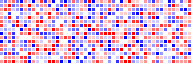
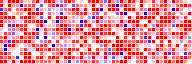
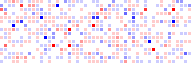
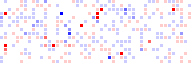
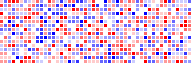
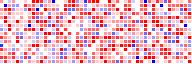
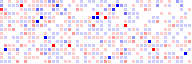
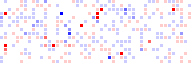
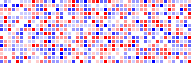
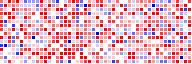
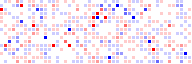
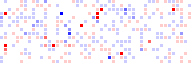
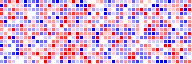
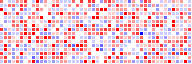
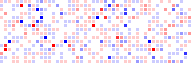
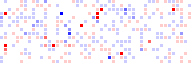
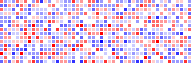
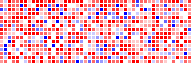
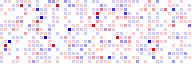
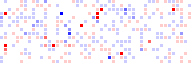
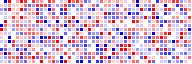
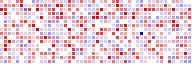
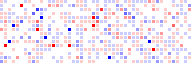
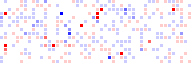
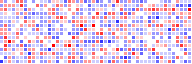
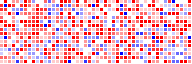
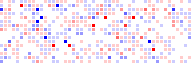
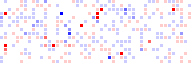
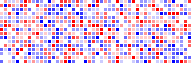
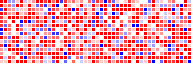
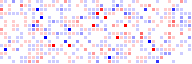
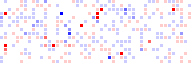
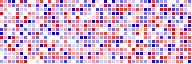
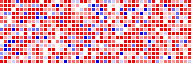
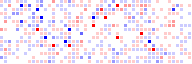
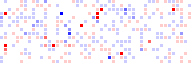
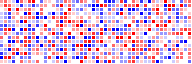
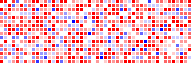
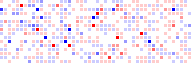
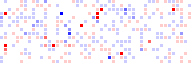
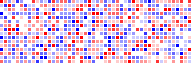
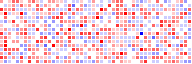
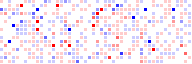
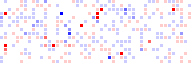
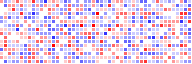
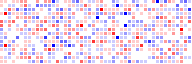
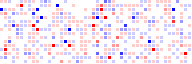
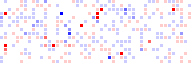
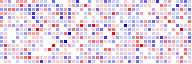

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,—,,,—,
a,1037,1,—,,,—,
44,4008,2,—,,,—,
-,1011,3,—,,,—,
year,2095,4,—,,,—,
-,1011,5,—,,,—,
old,2214,6,—,,,—,
woman,2450,7,—,,,—,
presented,3591,8,—,,,—,
with,2007,9,—,,,—,

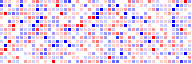
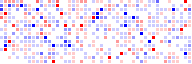
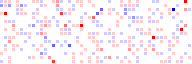
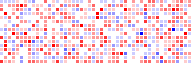
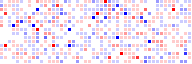
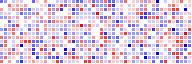
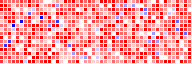
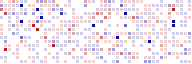
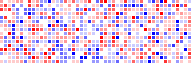
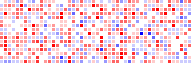
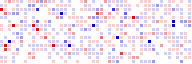
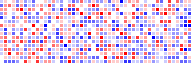
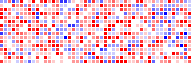
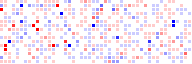
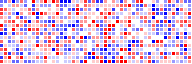
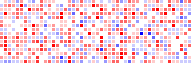
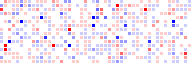
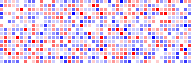
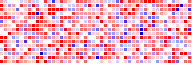
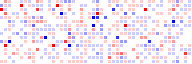
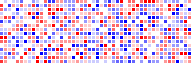
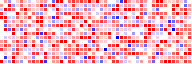
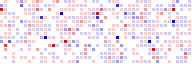
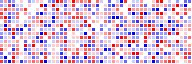
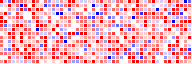
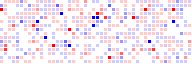
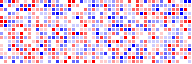
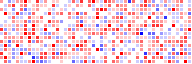
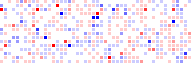
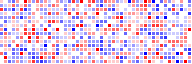
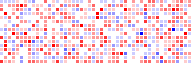
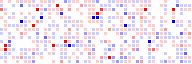
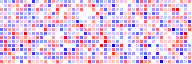
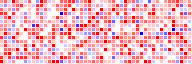
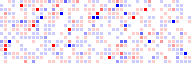
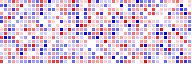
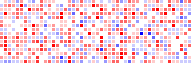
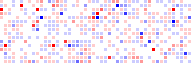
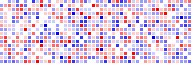
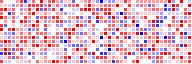
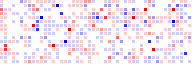
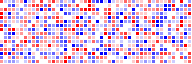
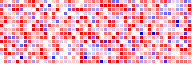
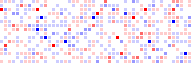
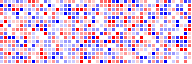
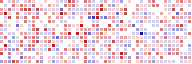
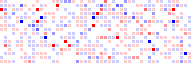
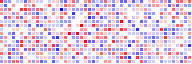
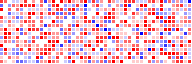
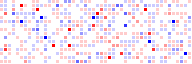
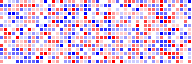
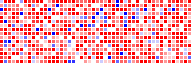
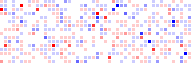
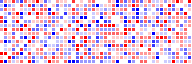
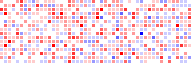
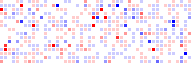
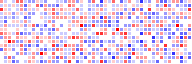
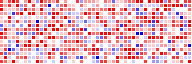
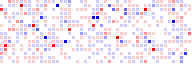
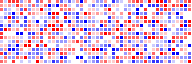
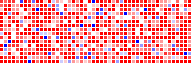
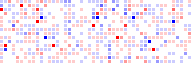
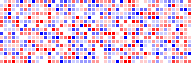
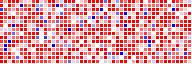
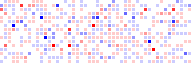
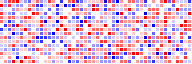
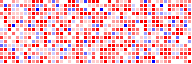
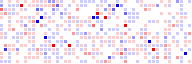
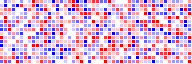
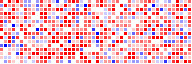
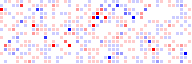
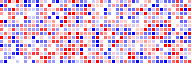
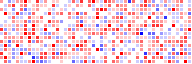
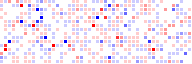
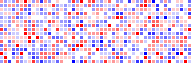
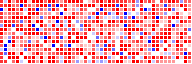
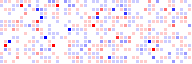
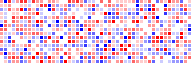
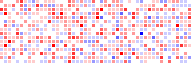
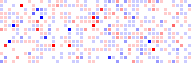
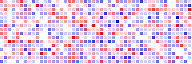
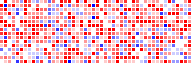
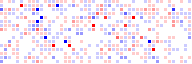
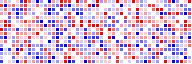
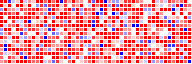
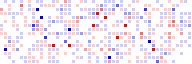
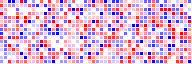
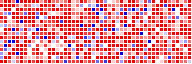
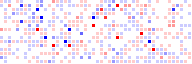
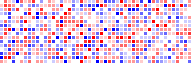
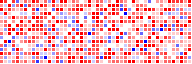
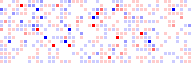
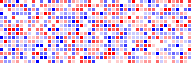
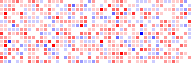
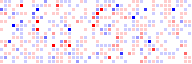
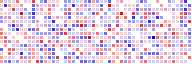
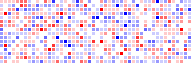
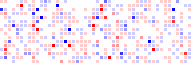
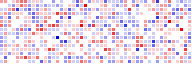

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],2,0,0,,,,
a,43,1,0,,,,
44,4044,2,0,,,,
-,17,3,0,,,,
year,2476,4,0,,,,
-,17,5,0,,,,
old,4156,6,0,,,,
woman,10440,7,0,,,,
presented,3549,8,0,,,,
with,1956,9,0,,,,

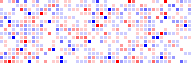
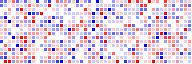
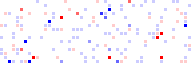
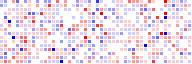
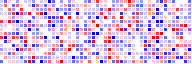
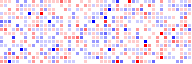
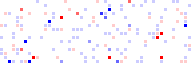
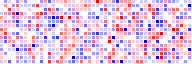
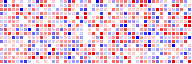
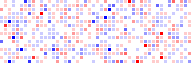
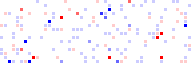
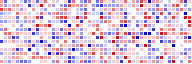
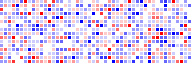
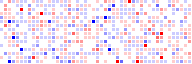
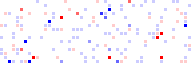
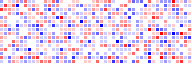
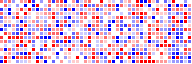
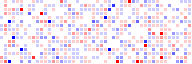
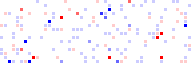
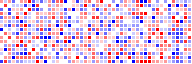
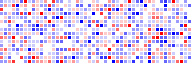
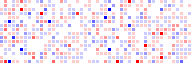
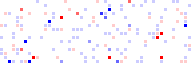
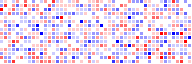
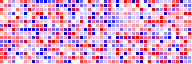
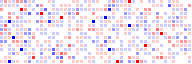
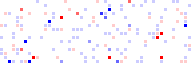
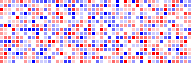
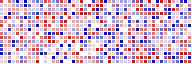
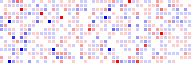
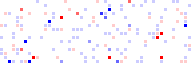
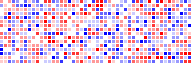
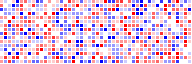
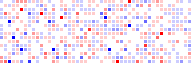
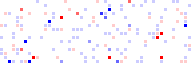
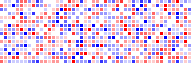
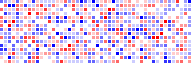
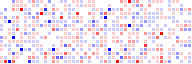
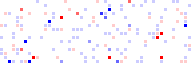
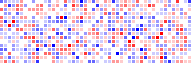
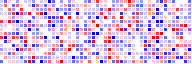
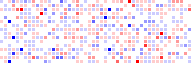
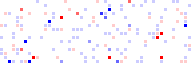
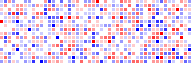
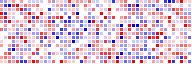
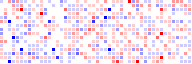
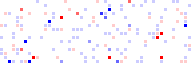
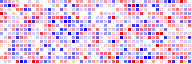
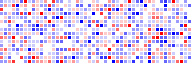
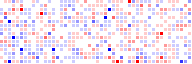
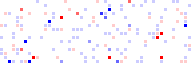
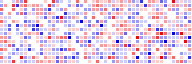
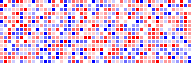
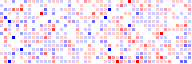
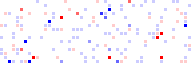
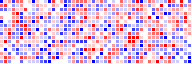
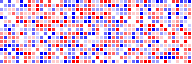
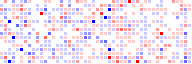
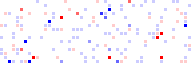
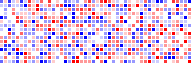
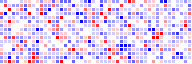
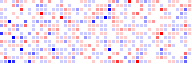
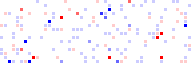
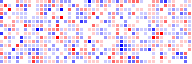
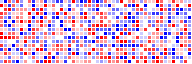
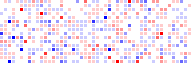
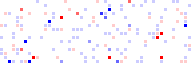
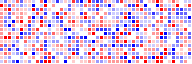
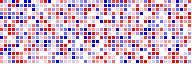
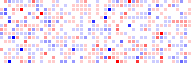
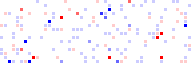
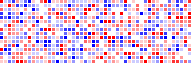
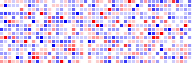
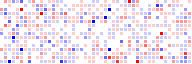
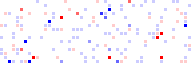
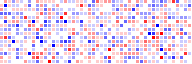
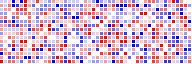
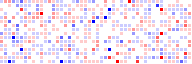
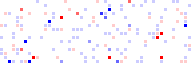
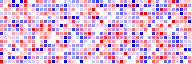
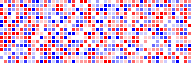
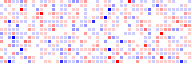
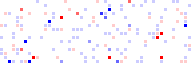
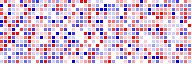
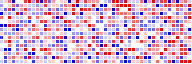
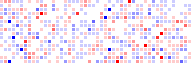
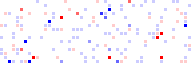
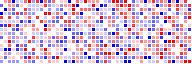
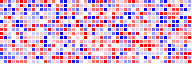
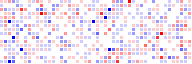
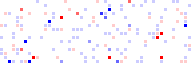
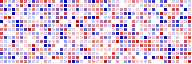
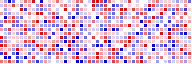
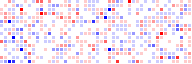
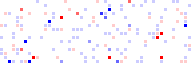
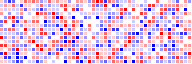
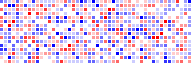
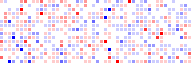
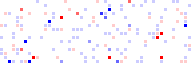
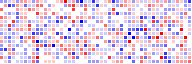
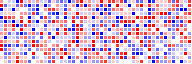
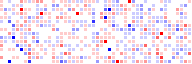
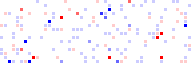
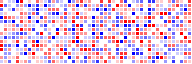
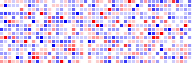
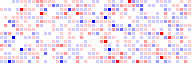
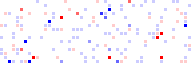
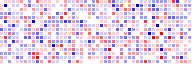
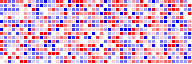
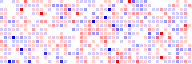
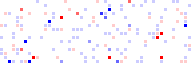
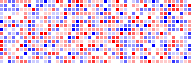
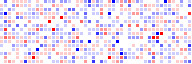
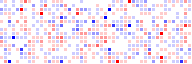
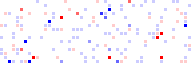
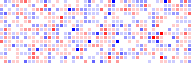
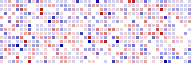
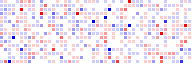
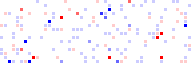
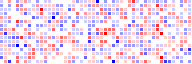

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
<s>,0,2,0,,,,
A,250,3,0,,,,
Ġ44,3550,4,0,,,,
-,12,5,0,,,,
year,180,6,0,,,,
-,12,7,0,,,,
old,279,8,0,,,,
Ġwoman,693,9,0,,,,
Ġpresented,2633,10,0,,,,
Ġwith,19,11,0,,,,

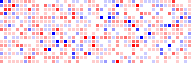
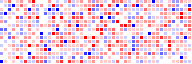
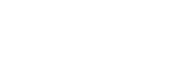
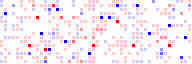
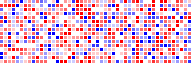
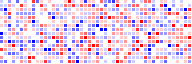
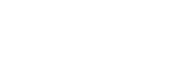
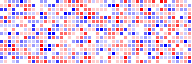
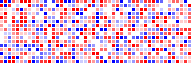
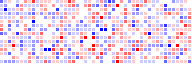
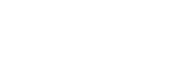
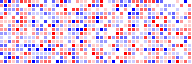
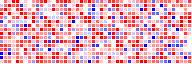
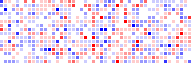
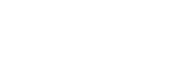
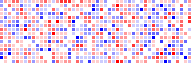
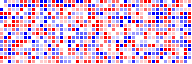
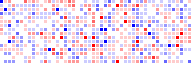
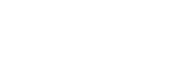
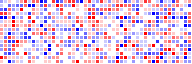
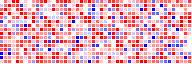
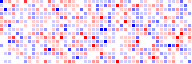
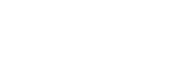
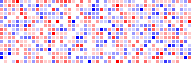
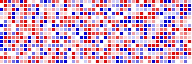
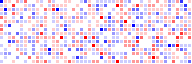
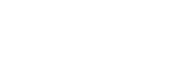
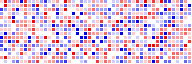
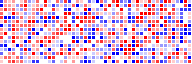
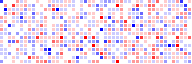
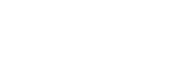
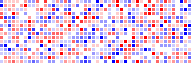
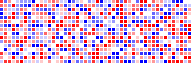
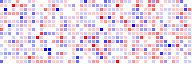
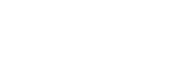
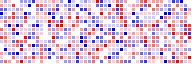
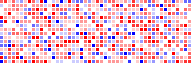
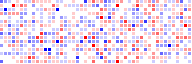
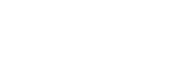
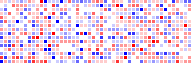
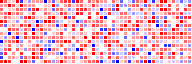
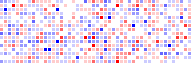
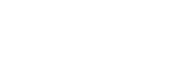
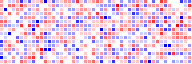
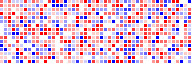
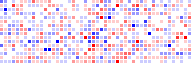
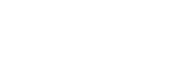
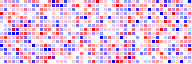
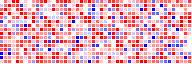
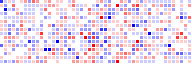
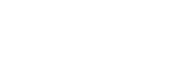
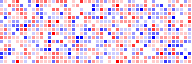
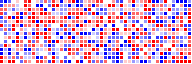
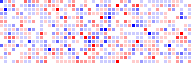
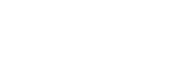
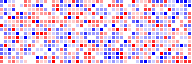
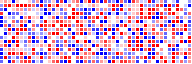
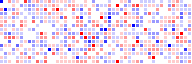
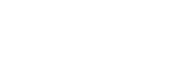
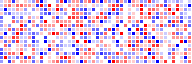
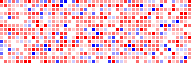
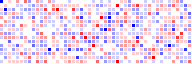
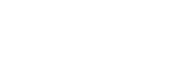
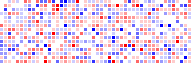
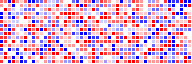
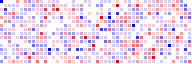
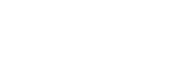
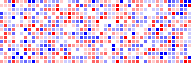
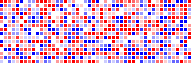
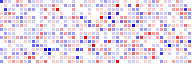
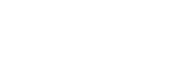
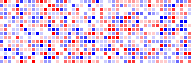
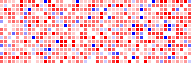
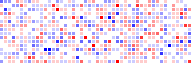
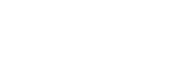
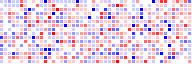
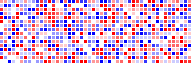
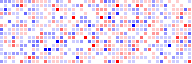
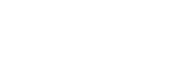
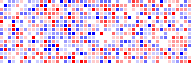
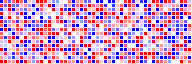
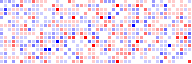
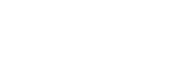
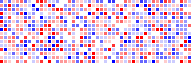
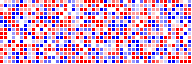
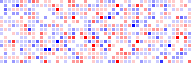
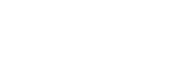
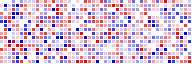
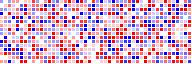
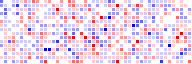
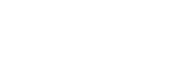
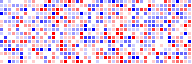
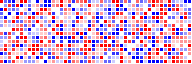
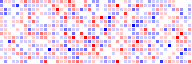
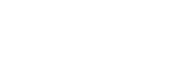
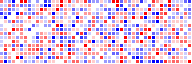
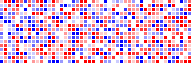
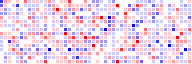
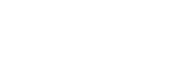
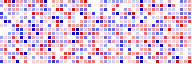
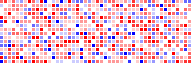
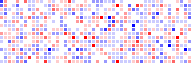
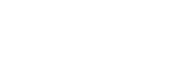
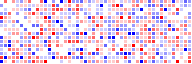
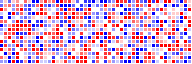
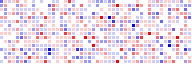
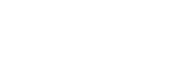
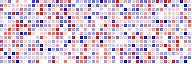
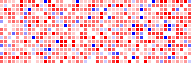
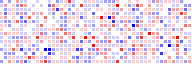
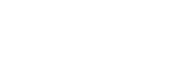
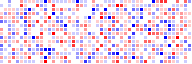
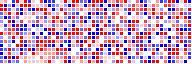
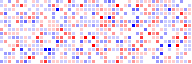
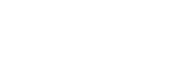
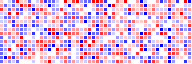
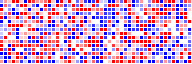
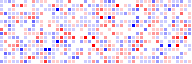
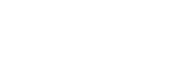
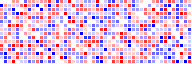
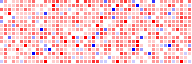
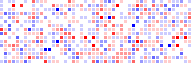
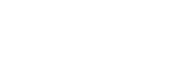
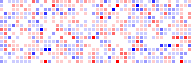
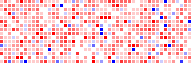
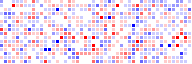
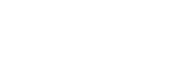
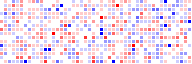

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],2,0,0,,,,
▁a,21,1,0,,,,
▁44,4576,2,0,,,,
-,8,3,0,,,,
year,731,4,0,,,,
-,8,5,0,,,,
old,1218,6,0,,,,
▁woman,524,7,0,,,,
▁presented,1831,8,0,,,,
▁with,29,9,0,,,,


token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
A,92,—,—,,—,—,—
44,4442,—,—,,—,—,—
-,9,—,—,,—,—,—
year,142,—,—,,—,—,—
-,9,—,—,,—,—,—
old,245,—,—,,—,—,—
woman,590,—,—,,—,—,—
presented,1935,—,—,,—,—,—
with,20,—,—,,—,—,—
a,7,—,—,,—,—,—


In [7]:
print(sentence, "\n")
for name, embedding in EMBEDDINGS.items():
    tokenizer = TOKENIZERS[embedding.tokenizer]
    show_embeddings(embedding(tokenizer.tokenize(sentence)), title=f"{name}   |   tokenizer: {embedding.tokenizer}")

## Two texts: where the segment matters

With a single text every token is in segment 0. BERT was also trained on
**pairs of texts** (`[CLS] text A [SEP] text B [SEP]`), and the segment
embedding is how it tells the two apart: segment 0 for the first text,
segment 1 for the second. Here, two fragments of the walkthrough sentence.
**Change the name** to compare (try `RoBERTa` and `DistilBERT (ner_pipeline)`).

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,0,,,,
abdominal,21419,1,0,,,,
pain,3255,2,0,,,,
[SEP],102,3,0,,,,
nausea,19029,4,1,,,,
and,1998,5,1,,,,
con,9530,6,1,,,,
##sti,16643,7,1,,,,
##pati,24952,8,1,,,,
##on,2239,9,1,,,,

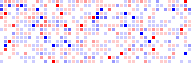
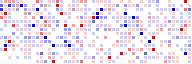
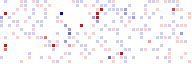
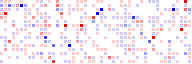
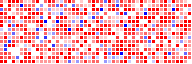
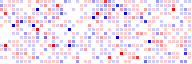
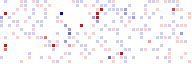
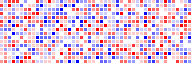
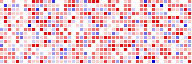
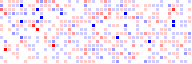
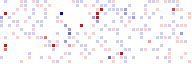
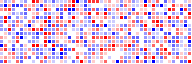
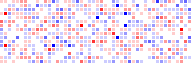
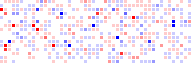
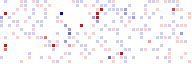
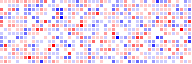
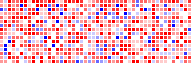
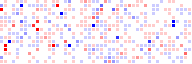
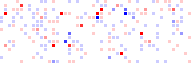
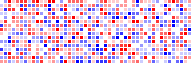
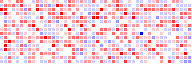
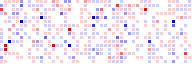
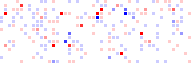
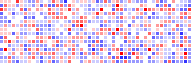
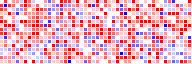
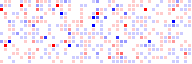
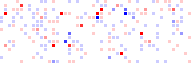
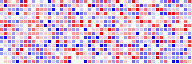
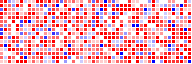
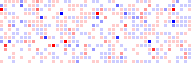
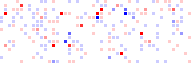
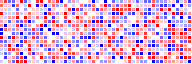
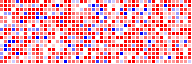
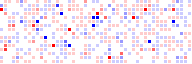
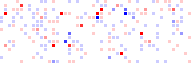
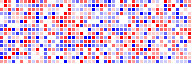
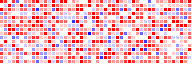
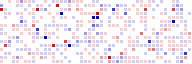
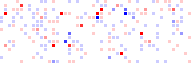
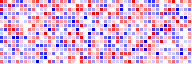
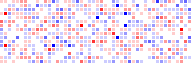
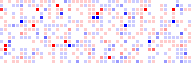
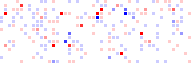
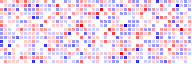

In [8]:
name = "BERT (uncased)"                         # ← change me
embedding = EMBEDDINGS[name]
tokenizer = TOKENIZERS[embedding.tokenizer]

text_a, text_b = "abdominal pain", "nausea and constipation"
show_embeddings(embedding(tokenizer.tokenize(text_a), tokenizer.tokenize(text_b)),
                title=f"{name}   |   tokenizer: {embedding.tokenizer}")

## Mixing: any tokenizer with any embedding

So far each embedding used its own tokenizer. You can also **choose the
pair yourself**: tokens are looked up by their text, so a token missing from
the embedding's vocabulary becomes `[UNK]` (or, for word vectors, a zero
vector). **Change both names.**

token,id,position,segment,token embedding,position embedding,segment embedding,layer 0 = LayerNorm(sum)
[CLS],101,0,0,,,,
A,100 = [UNK],1,0,,,,
44-year-old,100 = [UNK],2,0,,,,
woman,2450,3,0,,,,
presented,3591,4,0,,,,
with,2007,5,0,,,,
a,1037,6,0,,,,
3-day,100 = [UNK],7,0,,,,
history,2381,8,0,,,,
of,1997,9,0,,,,

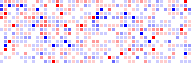
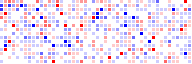
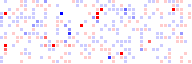
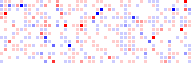
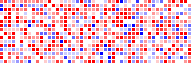
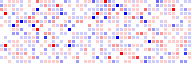
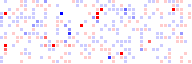
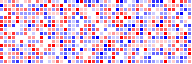
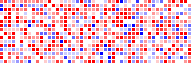
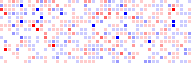
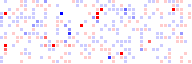
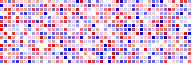
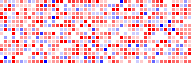
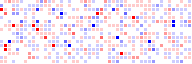
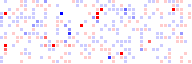
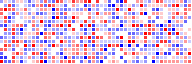
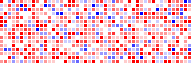
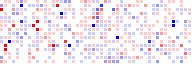
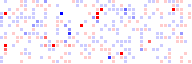
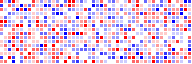
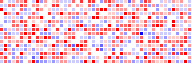
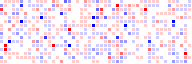
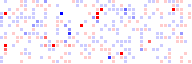
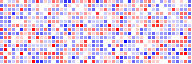
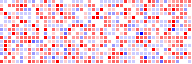
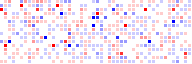
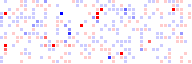
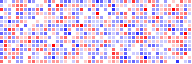
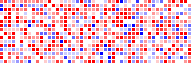
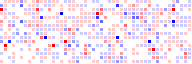
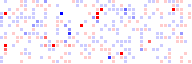
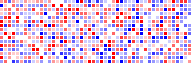
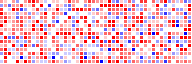
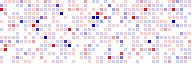
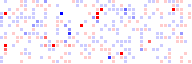
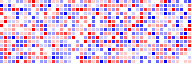
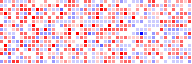
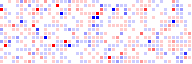
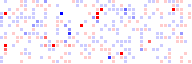
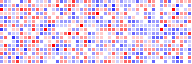
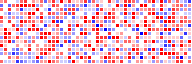
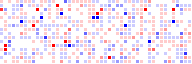
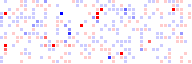
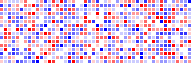
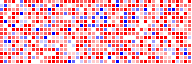
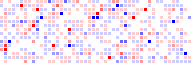
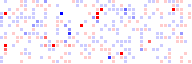
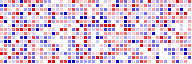
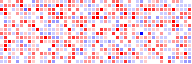
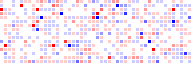
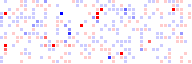
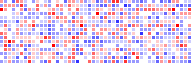
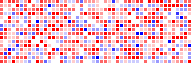
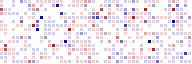
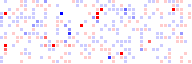
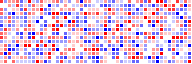
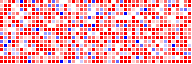
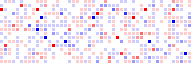
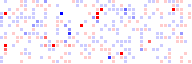
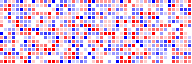
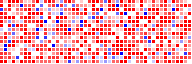
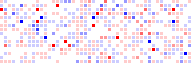
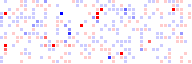
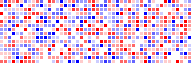
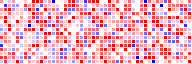
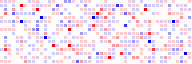
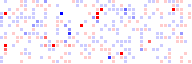
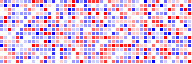
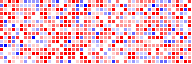
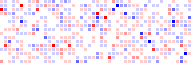
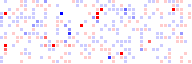
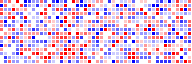
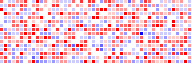
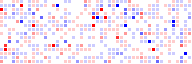
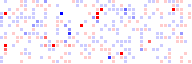
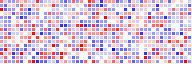
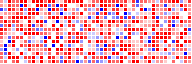
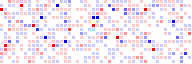
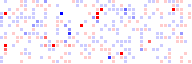
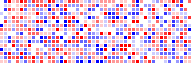
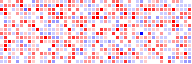
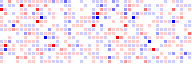
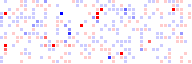
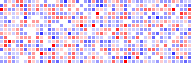
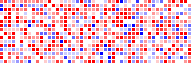
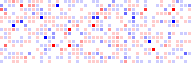
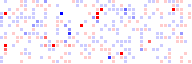
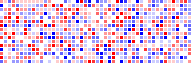
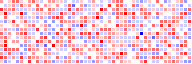
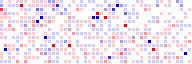
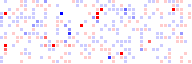
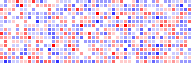
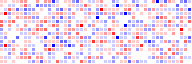
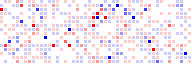
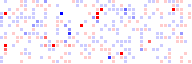
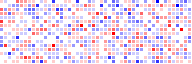

In [9]:
name = "BERT (uncased)"                         # ← change me
embedding = EMBEDDINGS[name]
tokenizer_name = "Rule-based (scispaCy)"        # ← change me: any key of TOKENIZERS
tokenizer = TOKENIZERS[tokenizer_name]

show_embeddings(embedding(tokenizer.tokenize(sentence)),
                title=f"{name}   |   tokenizer: {tokenizer_name}")

## Mixing, for every pair

How many tokens of the sentence each embedding **cannot find** in its
vocabulary (rows: tokenizer, columns: embedding). In the tables above those
are the rows whose `id` is not a number.

In [10]:
missing = {}
for name, embedding in EMBEDDINGS.items():
    missing[name] = {}
    for tokenizer_name, tokenizer in TOKENIZERS.items():
        table = embedding(tokenizer.tokenize(sentence))
        missing[name][tokenizer_name] = sum(isinstance(i, str) for i in table["id"])   # "100 = [UNK]", "— (not in the table ...)"
pd.DataFrame(missing)

,BERT (uncased),DistilBERT (ner_pipeline),BiomedBERT,RoBERTa,ALBERT,Word2Vec-style (spaCy)
Rule-based (scispaCy),4,4,3,8,11,2
Rule-based (spaCy),2,2,1,6,9,0
"WordPiece (BERT, uncased)",0,0,1,8,10,3
WordPiece (BiomedBERT),1,1,0,6,8,0
BPE (RoBERTa),23,23,23,0,22,21
Unigram (ALBERT),22,22,22,21,0,21


## What to notice

* **Static means "looked up".** A token's row in the token table never
  changes: `[CLS]` has the same boxes in every word table, and in the
  sentence the two `with` (positions 9 and 24 for BERT) have identical
  token embeddings.
* **Position is what tells them apart.** The two `with` get different
  position vectors, so their layer-0 vectors differ (compare the last
  column of the two rows). That is the only "context" a token has before the
  Transformer layers: *where* it is, not *what* surrounds it.
* **The three parts have different strengths.** On their shared color scale,
  the position vectors of BERT, DistilBERT, BiomedBERT and RoBERTa are paler
  than the token vectors; in ALBERT they are about as strong. LayerNorm then
  rescales the sum (its column has its own scale).
* **The segment** is the same vector for every token of a single text: it
  shifts all of them alike. It only says something with two texts, where it
  switches from 0 to 1 after the first `[SEP]`. RoBERTa has a single segment
  row (it separates the texts with `</s></s>` only) and DistilBERT — the
  model of `ner_pipeline.ipynb` — has no segment table at all.
* **The tables differ** (overview table): ALBERT's vectors have only **128**
  dimensions (fewer boxes; its first layer projects them to 768); RoBERTa has
  50,265 tokens and numbers positions from **2** (514 rows).
* **A domain vocabulary keeps clinical words whole**: with BiomedBERT,
  `constipation`, `dyspnea` and `echocardiography` are one row each
  (`[CLS]`, the word, `[SEP]`), with a vector learned for the whole word.
* **Word2Vec-style vectors** are a single lookup: no position, no segment,
  no LayerNorm — the token vector *is* the final vector, the same in every
  sentence. The table is pruned, so different words can share a row:
  `dyspnea` (word table) and `nausea` (sentence) both read row 18050 and
  have identical boxes. With scispaCy's tokens, `44-year-old` and `3-day`
  are not in the table at all: a zero vector (all white).
* **Mixing** shows why each model ships with its own tokenizer. With
  scispaCy's tokens, BERT finds no row for `A`, `44-year-old`, `3-day` and
  `constipation`: they all become `[UNK]` and get the very same vector. `A`
  fails because BERT's vocabulary is lower-case — lower-casing is a step of
  its tokenizer. RoBERTa's and ALBERT's tokens carry the space inside them
  (`Ġ`, `▁`), so the other embeddings miss most of them (21–23 tokens of
  the sentence). Only each embedding's own tokenizer gives zero.